# Task 6 — Machine Learning Model Development
### UniMatch AI — 10-Task Computational Intelligence Pipeline

**Input:** Feature Matrix from Task 5 (`feature_matrix_university.csv`, `feature_matrix_graduate.csv`, `selected_features.json`)

**Steps:** Train-test split → Logistic Regression → Decision Tree → Random Forest → SVM → XGBoost → Model evaluation → Best model selection & saving

**Deliverables:** ML Models (`.pkl`), Evaluation Report, ROC Curves, Confusion Matrix, Model Comparison Report

> **Two datasets, two targets, both used:**
> - **University Master (`feature_matrix_university.csv`)** — real binary target `admit` (0/1). This is the primary classification task.
> - **Graduate Admission (`feature_matrix_graduate.csv`)** — real target `chance_of_admit` is continuous (0-1), but Task 6 calls for classification models with ROC curves and a confusion matrix. To evaluate classification metrics on this dataset too, `chance_of_admit` is binarized at a 0.7 threshold into `admit_label` (1 if chance ≥ 0.7). This is a modeling decision made explicit here — if you'd rather keep this dataset as a regression problem, skip Section 2B/4B/5B and adapt the loop to `RandomForestRegressor`/`XGBRegressor` instead.


## 0. Setup

In [ ]:
import importlib, subprocess, sys

# Install only what's missing - avoids force-reinstall crashes that require a runtime restart.
required = ['pandas', 'numpy', 'scipy', 'sklearn', 'matplotlib', 'seaborn', 'xgboost', 'joblib', 'tabulate']
pip_names = {'sklearn': 'scikit-learn'}
for pkg in required:
    try:
        importlib.import_module(pkg)
    except ImportError:
        subprocess.run([sys.executable, '-m', 'pip', 'install', '-q', pip_names.get(pkg, pkg)])

import os, json
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import joblib

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.svm import SVC
from xgboost import XGBClassifier
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score, roc_auc_score,
    roc_curve, confusion_matrix, ConfusionMatrixDisplay, classification_report
)

pd.set_option('display.max_columns', 100)
sns.set_theme(style='whitegrid')
RANDOM_STATE = 42

out_dir = './task6_outputs'
os.makedirs(out_dir, exist_ok=True)
os.makedirs(f'{out_dir}/models', exist_ok=True)


## 1. Load Task 5 Outputs

Upload `feature_matrix_university.csv`, `feature_matrix_graduate.csv`, and `selected_features.json` to the Colab file browser before running (these are Task 5 deliverables), or mount Drive and adjust the paths below.

In [ ]:
uni_path = 'feature_matrix_university.csv'
grad_path = 'feature_matrix_graduate.csv'
selected_features_path = 'selected_features.json'

DRIVE_DIR = '/content/drive/MyDrive/UniMatch'
SEARCH_DIRS = ['.', './task5_outputs', DRIVE_DIR, f'{DRIVE_DIR}/task5_outputs']   # Task 5 saves to ./task5_outputs

def load_required(path):
    for d in SEARCH_DIRS:
        if os.path.exists(os.path.join(d, path)):
            return os.path.join(d, path)
    if not os.path.exists(path):
        try:
            from google.colab import files
            print(f"'{path}' not found - please upload it:")
            files.upload()
        except ModuleNotFoundError:
            raise FileNotFoundError(
                f"Could not find '{path}'. Place it in the same folder as this notebook, "
                "or mount Drive and update the path above."
            )
    return path

uni_df = pd.read_csv(load_required(uni_path))
grad_df = pd.read_csv(load_required(grad_path))

selected_features = None
selected_features_path = load_required(selected_features_path)
if os.path.exists(selected_features_path):
    with open(selected_features_path) as f:
        selected_features = json.load(f)
    print('Loaded selected_features.json:', list(selected_features.keys()) if isinstance(selected_features, dict) else selected_features)
else:
    print('selected_features.json not found - will fall back to using every numeric column except the target.')

if uni_df['admit'].isna().any():
    raise ValueError('feature_matrix_university.csv has rows without admit - the file is truncated; re-run Task 5 or load it from Drive.')
print('University Master feature matrix:', uni_df.shape)
print('Graduate Admission feature matrix:', grad_df.shape)
uni_df.head(3)


Loaded selected_features.json: ['university_dataset', 'graduate_dataset']
University Master feature matrix: (53527, 30)
Graduate Admission feature matrix: (500, 9)


,researchexp,industryexp,toeflscore,internexp,grev,greq,grea,toppercgpa,is_ranked,cgpa_pct,admit_chance_index,profile_distance,fit_score,program_Both MS and PhD,program_MS,program_MS/PhD,program_PhD,rank_tier_Tier 1,rank_tier_Tier 2,rank_tier_Tier 3,rank_tier_Tier 4,rank_tier_Unranked,department_label,department_freq,specialization_label,specialization_freq,univname_label,univname_freq,admit,split
0,0,18,112.0,5.0,160.0,167.0,4.5,8.9,0,85.00,0.669932,1.301075,0.434580,0,1,0,0,0,0,0,0,1,998,0.001102,2473,0.002429,53,0.002877,1,train
1,0,0,106.0,0.0,153.0,166.0,3.5,0.0,0,58.00,0.433317,0.582679,0.631840,0,1,0,0,0,0,0,0,1,1,0.037738,2926,0.429279,53,0.002877,1,train
2,0,66,94.0,0.0,146.0,157.0,3.0,81.0,0,78.28,0.423925,0.973118,0.506812,0,1,0,0,0,0,0,0,1,292,0.040783,2926,0.429279,53,0.002877,1,test


## 2. Prepare Features & Targets

### 2A. University Master dataset (`admit`, real binary target)

In [ ]:
TARGET_A = 'admit'

def get_selected_cols(sel, key_candidates, fallback_df, target_col):
    """Pull the feature list from selected_features.json (Task 5 saves it under
    'university_dataset' / 'graduate_dataset'). Falls back to every numeric column
    except the target - and says so loudly, since that silently ignores Task 5's selection."""
    if isinstance(sel, dict):
        for k in key_candidates:
            if k in sel:
                cols = sel[k]
                return [c for c in cols if c in fallback_df.columns and c != target_col]
    print('WARNING: selected features not found in JSON - using ALL numeric columns.')
    return [c for c in fallback_df.select_dtypes(include=[np.number]).columns if c != target_col]

feature_cols_a = get_selected_cols(
    selected_features, ['university_dataset', 'university'], uni_df, TARGET_A
)
print(f'University Master: {len(feature_cols_a)} selected features')
print(feature_cols_a)

X_a = uni_df[feature_cols_a].copy()
y_a = uni_df[TARGET_A].copy()

# Safety net: fill any leftover NaNs with the column median (should be rare after Tasks 4-5)
na_counts = X_a.isna().sum()
if na_counts.sum() > 0:
    print('Filling remaining NaNs with column median:')
    print(na_counts[na_counts > 0])
    X_a = X_a.fillna(X_a.median(numeric_only=True))

print('Class balance (admit):')
print(y_a.value_counts(normalize=True).round(3))


University Master: 15 selected features
['univname_freq', 'univname_label', 'cgpa_pct', 'admit_chance_index', 'profile_distance', 'department_label', 'grev', 'toeflscore', 'greq', 'specialization_freq', 'toppercgpa', 'specialization_label', 'department_freq', 'grea', 'industryexp']
Class balance (admit):
admit
1    0.522
0    0.478
Name: proportion, dtype: float64


### 2B. Graduate Admission dataset (`chance_of_admit`, binarized at 0.7)

`chance_of_admit` is a real continuous label. It's binarized here (`admit_label = 1` if `chance_of_admit >= 0.7`) so this dataset can go through the same classification pipeline (ROC curve, confusion matrix).

**Why 0.7 and not 0.5:** almost every applicant has chance ≥ 0.5, so a 0.5 cut left only ~7% negatives — just 7 rows in the test set, far too few for stable precision/recall. 0.7 is close to the median, gives a reasonably balanced target, and reads naturally as "good chance of admission". Change `THRESHOLD` if your project defines success differently.


In [ ]:
TARGET_B_RAW = 'chance_of_admit'
THRESHOLD = 0.7

feature_cols_b = get_selected_cols(
    selected_features, ['graduate_dataset', 'graduate'], grad_df, TARGET_B_RAW
)
print(f'Graduate Admission: {len(feature_cols_b)} selected features')
print(feature_cols_b)

X_b = grad_df[feature_cols_b].copy()
y_b_continuous = grad_df[TARGET_B_RAW].copy()
y_b = (y_b_continuous >= THRESHOLD).astype(int)

if X_b.isna().sum().sum() > 0:
    X_b = X_b.fillna(X_b.median(numeric_only=True))

print(f'Binarized at {THRESHOLD}: class balance (admit_label):')
print(y_b.value_counts(normalize=True).round(3))


Graduate Admission: 3 selected features
['admit_chance_index', 'toefl_score', 'sop']
Binarized at 0.7: class balance (admit_label):
chance_of_admit
1    0.6
0    0.4
Name: proportion, dtype: float64


## 3. Train-Test Split

In [ ]:
# Dataset A: REUSE the split saved by Task 5. fit_score's cohort statistics were computed from
# those train rows only, so a fresh random split here would put rows the feature "saw" into the test set.
if 'split' in uni_df.columns:
    is_train = uni_df['split'] == 'train'
    X_a_train, X_a_test = X_a[is_train], X_a[~is_train]
    y_a_train, y_a_test = y_a[is_train], y_a[~is_train]
else:
    print("WARNING: no 'split' column from Task 5 - falling back to a new random split.")
    X_a_train, X_a_test, y_a_train, y_a_test = train_test_split(
        X_a, y_a, test_size=0.2, random_state=RANDOM_STATE, stratify=y_a
    )
X_b_train, X_b_test, y_b_train, y_b_test = train_test_split(
    X_b, y_b, test_size=0.2, random_state=RANDOM_STATE, stratify=y_b
)

print(f'University Master  - train: {X_a_train.shape}, test: {X_a_test.shape}')
print(f'Graduate Admission - train: {X_b_train.shape}, test: {X_b_test.shape}')

# Scale features (needed for Logistic Regression and SVM; harmless for tree-based models
# since they're scale-invariant, but a single consistent matrix keeps the loop simple).
# IMPORTANT: fit the scaler on TRAIN ONLY, then transform test, to avoid leakage.
scaler_a = StandardScaler().fit(X_a_train)
X_a_train_scaled = pd.DataFrame(scaler_a.transform(X_a_train), columns=X_a_train.columns, index=X_a_train.index)
X_a_test_scaled = pd.DataFrame(scaler_a.transform(X_a_test), columns=X_a_test.columns, index=X_a_test.index)

scaler_b = StandardScaler().fit(X_b_train)
X_b_train_scaled = pd.DataFrame(scaler_b.transform(X_b_train), columns=X_b_train.columns, index=X_b_train.index)
X_b_test_scaled = pd.DataFrame(scaler_b.transform(X_b_test), columns=X_b_test.columns, index=X_b_test.index)


University Master  - train: (42821, 15), test: (10706, 15)
Graduate Admission - train: (400, 3), test: (100, 3)


## 4. Model Training

Five models per dataset, per the project plan: Logistic Regression, Decision Tree, Random Forest, SVM, XGBoost. Linear/distance-based models (Logistic Regression, SVM) use the scaled features; tree-based models (Decision Tree, Random Forest, XGBoost) use the unscaled features, since splits are scale-invariant.

In [ ]:
def class_imbalance_ratio(y_train):
    """neg/pos ratio of the training labels - used to set XGBoost's scale_pos_weight
    (which has no 'balanced' option of its own, unlike sklearn's class_weight)."""
    counts = y_train.value_counts()
    pos = counts.get(1, 1)
    neg = counts.get(0, 1)
    return neg / pos

def build_models(y_train):
    """Fresh set of unfit model instances, class-weighted to the ACTUAL imbalance of
    y_train. class_weight='balanced' re-weights each class inversely proportional to its
    frequency, so a model can't just predict the majority class and call it a day - it's
    penalized more for getting minority-class (typically the smaller 'admit' group) rows
    wrong. XGBoost doesn't have a class_weight option, so it gets the equivalent via
    scale_pos_weight instead. Called once per dataset (fresh dict) so estimators from
    dataset A never leak into dataset B's dict, and so each dataset gets weights matched
    to its own class balance rather than a shared hardcoded value.
    """
    spw = class_imbalance_ratio(y_train)
    print(f'  class balance -> neg/pos ratio: {spw:.3f} (used as XGBoost scale_pos_weight)')
    return {
        'Logistic Regression': (LogisticRegression(max_iter=1000, class_weight='balanced', random_state=RANDOM_STATE), True),
        'Decision Tree':       (DecisionTreeClassifier(max_depth=8, class_weight='balanced', random_state=RANDOM_STATE), False),
        'Random Forest':       (RandomForestClassifier(n_estimators=300, max_depth=12, class_weight='balanced', random_state=RANDOM_STATE, n_jobs=-1), False),
        'SVM':                 (SVC(kernel='rbf', probability=True, class_weight='balanced', random_state=RANDOM_STATE), True),
        'XGBoost':             (XGBClassifier(n_estimators=300, max_depth=6, learning_rate=0.1, scale_pos_weight=spw,
                                                random_state=RANDOM_STATE, eval_metric='logloss', n_jobs=-1), False),
    }
    # (name -> (estimator, needs_scaled_features))

def train_all(models, X_train, X_train_scaled, y_train):
    fitted = {}
    for name, (model, needs_scaled) in models.items():
        Xtr = X_train_scaled if needs_scaled else X_train
        model.fit(Xtr, y_train)
        fitted[name] = (model, needs_scaled)
        print(f'  trained: {name}')
    return fitted


In [ ]:
print('Training on University Master (target: admit)...')
models_a = build_models(y_a_train)
fitted_a = train_all(models_a, X_a_train, X_a_train_scaled, y_a_train)


Training on University Master (target: admit)...
  class balance -> neg/pos ratio: 0.917 (used as XGBoost scale_pos_weight)
  trained: Logistic Regression
  trained: Decision Tree
  trained: Random Forest
  trained: SVM
  trained: XGBoost


In [ ]:
print('Training on Graduate Admission (target: admit_label, chance_of_admit >= %.2f)...' % THRESHOLD)
models_b = build_models(y_b_train)
fitted_b = train_all(models_b, X_b_train, X_b_train_scaled, y_b_train)


Training on Graduate Admission (target: admit_label, chance_of_admit >= 0.70)...
  class balance -> neg/pos ratio: 0.667 (used as XGBoost scale_pos_weight)
  trained: Logistic Regression
  trained: Decision Tree
  trained: Random Forest
  trained: SVM
  trained: XGBoost


## 5. Model Evaluation

Accuracy, precision, recall, F1, and ROC-AUC for every model, plus ROC curves and confusion matrices.

In [ ]:
def evaluate_models(fitted, X_test, X_test_scaled, y_test, dataset_label):
    """Reports overall metrics (class 1 = 'positive'/admit, as before) PLUS explicit
    minority-class metrics. Whichever class is smaller in y_test is reported separately,
    since with an imbalanced target the overall/'positive-class' numbers can look great
    (e.g. recall=1.0) purely by favoring the majority class - that's exactly the failure
    mode class_weight='balanced' (see build_models) is meant to prevent, so it's worth
    confirming it actually worked by looking at the minority class on its own.
    """
    class_counts = y_test.value_counts()
    minority_class = int(class_counts.idxmin())
    print(f'{dataset_label}: minority class in test set = {minority_class} '
          f'({class_counts.min()}/{len(y_test)} = {class_counts.min()/len(y_test)*100:.1f}%)')

    rows = []
    roc_data = {}
    for name, (model, needs_scaled) in fitted.items():
        Xte = X_test_scaled if needs_scaled else X_test
        y_pred = model.predict(Xte)
        y_proba = model.predict_proba(Xte)[:, 1] if hasattr(model, 'predict_proba') else None

        row = {
            'model': name,
            'accuracy': accuracy_score(y_test, y_pred),
            'precision': precision_score(y_test, y_pred, zero_division=0),
            'recall': recall_score(y_test, y_pred, zero_division=0),
            'f1': f1_score(y_test, y_pred, zero_division=0),
            f'precision_minority(class {minority_class})': precision_score(
                y_test, y_pred, pos_label=minority_class, zero_division=0),
            f'recall_minority(class {minority_class})': recall_score(
                y_test, y_pred, pos_label=minority_class, zero_division=0),
            f'f1_minority(class {minority_class})': f1_score(
                y_test, y_pred, pos_label=minority_class, zero_division=0),
        }
        if y_proba is not None:
            row['roc_auc'] = roc_auc_score(y_test, y_proba)
            fpr, tpr, _ = roc_curve(y_test, y_proba)
            roc_data[name] = (fpr, tpr, row['roc_auc'])
        else:
            row['roc_auc'] = np.nan
        rows.append(row)

    results = pd.DataFrame(rows).sort_values('roc_auc', ascending=False).reset_index(drop=True)
    print(f'--- {dataset_label}: evaluation results ---')
    display(results)
    return results, roc_data


In [ ]:
results_a, roc_data_a = evaluate_models(fitted_a, X_a_test, X_a_test_scaled, y_a_test, 'University Master (admit)')


University Master (admit): minority class in test set = 0 (5121/10706 = 47.8%)
--- University Master (admit): evaluation results ---


,model,accuracy,precision,recall,f1,precision_minority(class 0),recall_minority(class 0),f1_minority(class 0),roc_auc
0,XGBoost,0.728937,0.750795,0.719069,0.734589,0.707112,0.739699,0.723039,0.800454
1,Random Forest,0.697553,0.721876,0.683617,0.702225,0.673805,0.712751,0.692731,0.767123
2,Decision Tree,0.673828,0.678553,0.712086,0.694915,0.668111,0.632103,0.649609,0.726332
3,SVM,0.648515,0.674521,0.630439,0.651735,0.623770,0.668229,0.645234,0.708399
4,Logistic Regression,0.576406,0.600229,0.562936,0.580985,0.553584,0.591095,0.571725,0.608057


In [ ]:
results_b, roc_data_b = evaluate_models(fitted_b, X_b_test, X_b_test_scaled, y_b_test, 'Graduate Admission (admit_label)')


Graduate Admission (admit_label): minority class in test set = 0 (40/100 = 40.0%)
--- Graduate Admission (admit_label): evaluation results ---


,model,accuracy,precision,recall,f1,precision_minority(class 0),recall_minority(class 0),f1_minority(class 0),roc_auc
0,Logistic Regression,0.90,0.931034,0.900000,0.915254,0.857143,0.900,0.878049,0.947917
1,SVM,0.89,0.915254,0.900000,0.907563,0.853659,0.875,0.864198,0.933750
2,Random Forest,0.87,0.873016,0.916667,0.894309,0.864865,0.800,0.831169,0.921875
3,XGBoost,0.83,0.864407,0.850000,0.857143,0.780488,0.800,0.790123,0.907083
4,Decision Tree,0.84,0.892857,0.833333,0.862069,0.772727,0.850,0.809524,0.873125


### 5.1 ROC Curves

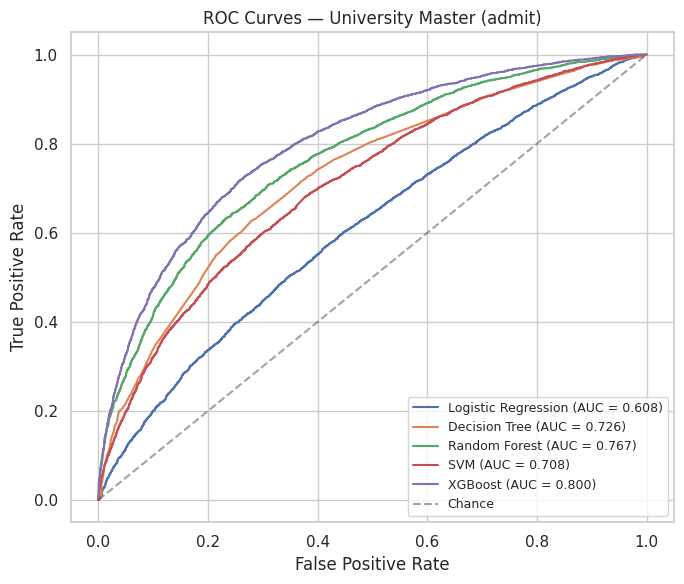

In [ ]:
def plot_roc_curves(roc_data, title, save_path):
    plt.figure(figsize=(7, 6))
    for name, (fpr, tpr, auc) in roc_data.items():
        plt.plot(fpr, tpr, label=f'{name} (AUC = {auc:.3f})')
    plt.plot([0, 1], [0, 1], 'k--', alpha=0.4, label='Chance')
    plt.xlabel('False Positive Rate')
    plt.ylabel('True Positive Rate')
    plt.title(title)
    plt.legend(loc='lower right', fontsize=9)
    plt.tight_layout()
    plt.savefig(save_path, dpi=150)
    plt.show()

plot_roc_curves(roc_data_a, 'ROC Curves — University Master (admit)', f'{out_dir}/roc_curves_university.png')


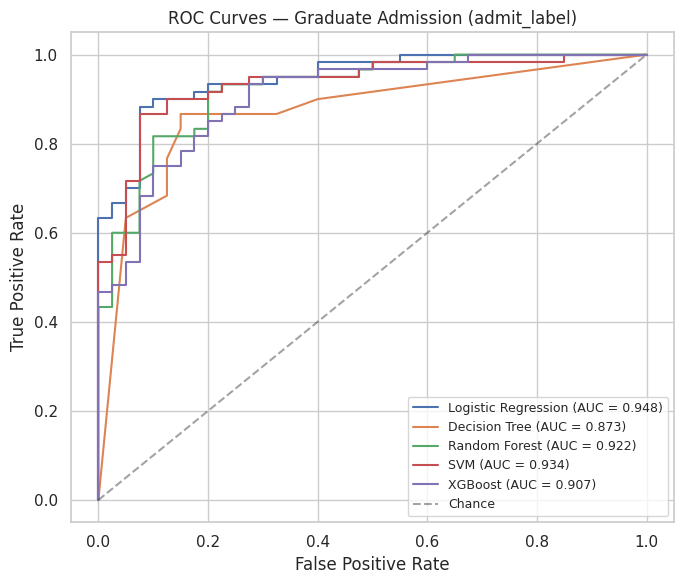

In [ ]:
plot_roc_curves(roc_data_b, 'ROC Curves — Graduate Admission (admit_label)', f'{out_dir}/roc_curves_graduate.png')


### 5.2 Confusion Matrices

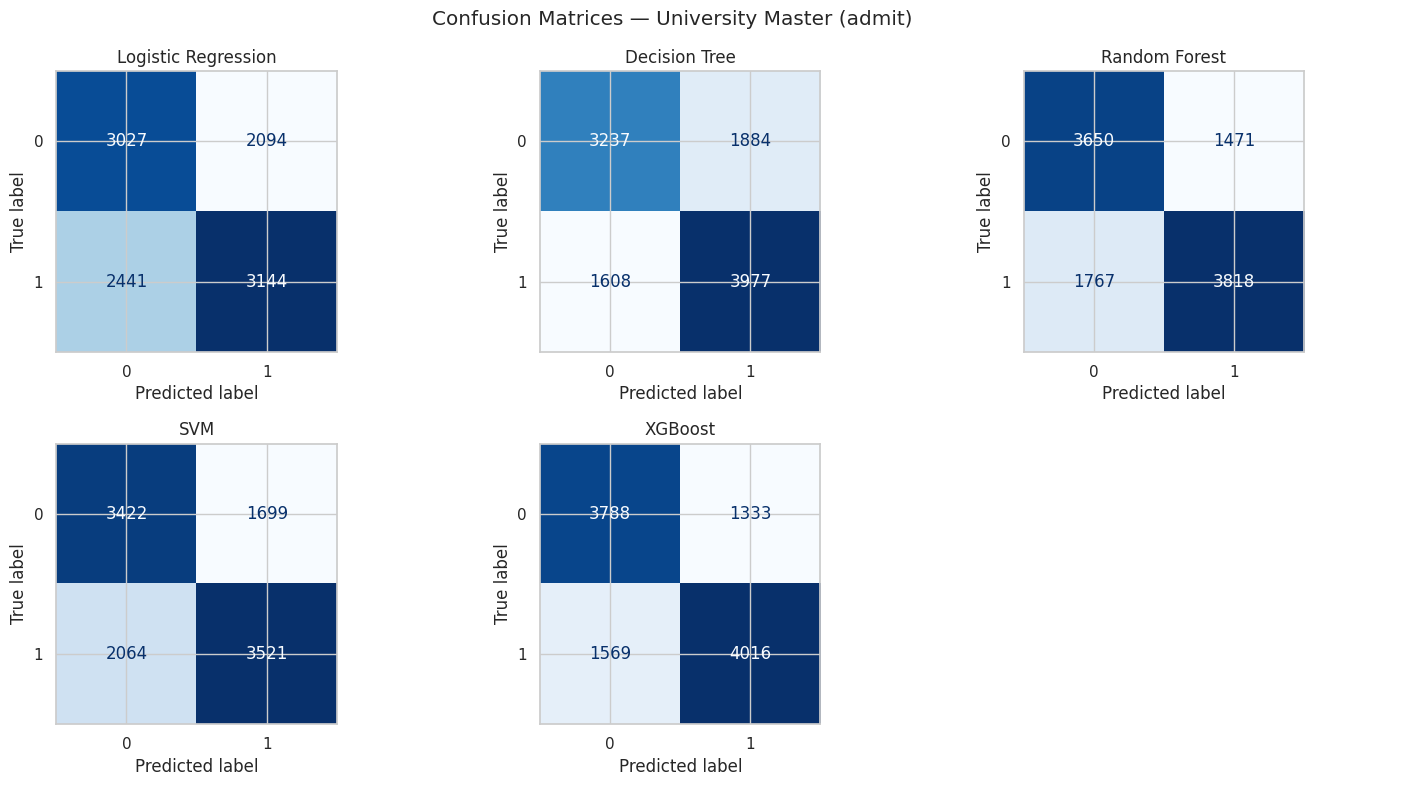

In [ ]:
def plot_confusion_matrices(fitted, X_test, X_test_scaled, y_test, title, save_path):
    n = len(fitted)
    ncols = 3
    nrows = int(np.ceil(n / ncols))
    fig, axes = plt.subplots(nrows, ncols, figsize=(5*ncols, 4*nrows))
    axes = np.array(axes).reshape(-1)
    for ax, (name, (model, needs_scaled)) in zip(axes, fitted.items()):
        Xte = X_test_scaled if needs_scaled else X_test
        y_pred = model.predict(Xte)
        cm = confusion_matrix(y_test, y_pred)
        ConfusionMatrixDisplay(cm).plot(ax=ax, colorbar=False, cmap='Blues')
        ax.set_title(name)
    for ax in axes[len(fitted):]:
        ax.axis('off')
    plt.suptitle(title)
    plt.tight_layout()
    plt.savefig(save_path, dpi=150)
    plt.show()

plot_confusion_matrices(fitted_a, X_a_test, X_a_test_scaled, y_a_test,
                         'Confusion Matrices — University Master (admit)', f'{out_dir}/confusion_matrices_university.png')


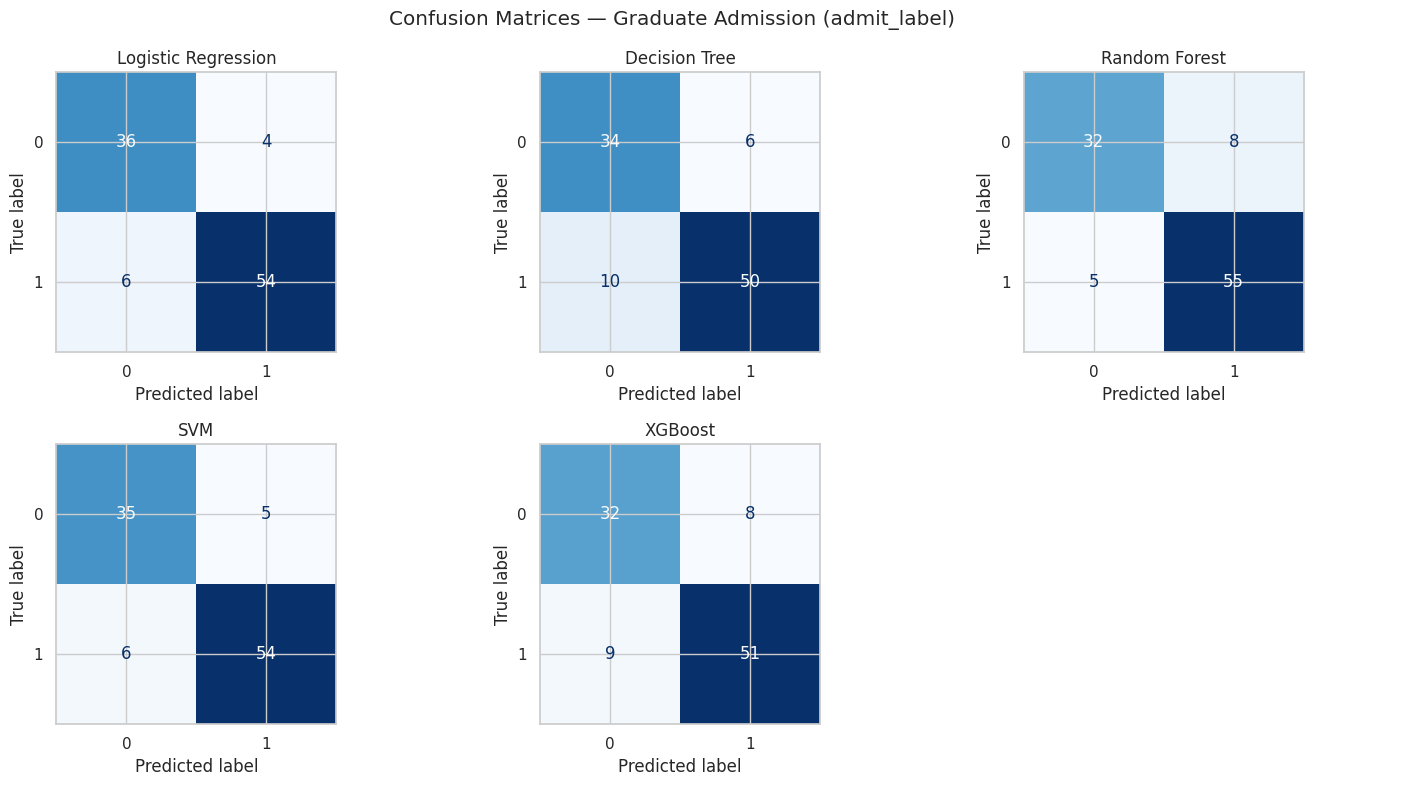

In [ ]:
plot_confusion_matrices(fitted_b, X_b_test, X_b_test_scaled, y_b_test,
                         'Confusion Matrices — Graduate Admission (admit_label)', f'{out_dir}/confusion_matrices_graduate.png')


## 6. Best Model Selection & Saving

Best model per dataset = highest ROC-AUC on the held-out test set. All five models per dataset are saved (not just the best), so Task 8's explainability work and Task 9's deployment can compare or swap models later; the report explicitly calls out which one was selected as best.

In [ ]:
def save_models(fitted, out_subdir):
    os.makedirs(f'{out_dir}/models/{out_subdir}', exist_ok=True)
    for name, (model, needs_scaled) in fitted.items():
        fname = name.lower().replace(' ', '_')
        path = f'{out_dir}/models/{out_subdir}/{fname}.pkl'
        joblib.dump(model, path)
    print(f'Saved {len(fitted)} models to {out_dir}/models/{out_subdir}/')

save_models(fitted_a, 'university')
save_models(fitted_b, 'graduate')

# Save the fitted scalers too - required to correctly transform new data for LR/SVM at inference time
joblib.dump(scaler_a, f'{out_dir}/models/university/scaler.pkl')
joblib.dump(scaler_b, f'{out_dir}/models/graduate/scaler.pkl')

# Save the exact feature order each model expects (needed by Tasks 8-9)
with open(f'{out_dir}/models/feature_columns.json', 'w') as f:
    json.dump({'university': feature_cols_a, 'graduate': feature_cols_b, 'graduate_threshold': THRESHOLD}, f, indent=2)

best_model_a = results_a.iloc[0]['model']
best_model_b = results_b.iloc[0]['model']
print(f'Best model - University Master:  {best_model_a} (ROC-AUC = {results_a.iloc[0]["roc_auc"]:.4f})')
print(f'Best model - Graduate Admission: {best_model_b} (ROC-AUC = {results_b.iloc[0]["roc_auc"]:.4f})')


Saved 5 models to ./task6_outputs/models/university/
Saved 5 models to ./task6_outputs/models/graduate/
Best model - University Master:  XGBoost (ROC-AUC = 0.8005)
Best model - Graduate Admission: Logistic Regression (ROC-AUC = 0.9479)


## 7. Deliverables

In [ ]:
# 1. Evaluation Report (CSV, per dataset)
results_a.to_csv(f'{out_dir}/evaluation_report_university.csv', index=False)
results_b.to_csv(f'{out_dir}/evaluation_report_graduate.csv', index=False)

# 2. Model Comparison Report (markdown, both datasets side by side)
comparison_md = f'''# Model Comparison Report — Task 6

## University Master dataset (target: `admit`)
{results_a.to_markdown(index=False)}

**Best model: {best_model_a}** (ROC-AUC = {results_a.iloc[0]['roc_auc']:.4f})

## Graduate Admission dataset (target: `admit_label`, chance_of_admit >= {THRESHOLD})
{results_b.to_markdown(index=False)}

**Best model: {best_model_b}** (ROC-AUC = {results_b.iloc[0]['roc_auc']:.4f})

## Notes
- Linear/distance-based models (Logistic Regression, SVM) were trained on StandardScaler-scaled
  features (scaler fit on the training split only, to avoid leakage). Tree-based models
  (Decision Tree, Random Forest, XGBoost) were trained on unscaled features.
- The Graduate Admission dataset's real target is a continuous admission probability
  (`chance_of_admit`); it was binarized at {THRESHOLD} to allow classification-style evaluation
  (ROC curve, confusion matrix) as called for in the Task 6 plan. If a continuous prediction is
  preferred, swap the classifiers for regressors (`RandomForestRegressor`, `XGBRegressor`, etc.)
  and evaluate with regression metrics (MAE, RMSE, R^2) instead.
- All five trained models per dataset are saved under `models/university/` and `models/graduate/`,
  not just the best one, so later tasks can compare or swap models.
- **Class imbalance handling:** every model uses `class_weight='balanced'` (XGBoost uses the
  equivalent `scale_pos_weight`, computed automatically from each dataset's own train-split class
  ratio) so the minority class isn't ignored in favor of trivially predicting the majority class.
  The evaluation tables above report both the standard class-1 metrics and explicit
  minority-class precision/recall/F1, since for the Graduate Admission dataset class 1 (admit) is
  the majority class - the minority-class columns are the more meaningful check on
  whether the model is doing real work rather than coasting on class balance.
- The University Master train/test split is the one created in Task 5 (Fit Score's admitted-cohort
  statistics use training rows only), so test-set outcomes never influence the features.
'''

with open(f'{out_dir}/model_comparison_report.md', 'w') as f:
    f.write(comparison_md)

print(comparison_md)


# Model Comparison Report — Task 6

## University Master dataset (target: `admit`)
| model               |   accuracy |   precision |   recall |       f1 |   precision_minority(class 0) |   recall_minority(class 0) |   f1_minority(class 0) |   roc_auc |
|:--------------------|-----------:|------------:|---------:|---------:|------------------------------:|---------------------------:|-----------------------:|----------:|
| XGBoost             |   0.728937 |    0.750795 | 0.719069 | 0.734589 |                      0.707112 |                   0.739699 |               0.723039 |  0.800454 |
| Random Forest       |   0.697553 |    0.721876 | 0.683617 | 0.702225 |                      0.673805 |                   0.712751 |               0.692731 |  0.767123 |
| Decision Tree       |   0.673828 |    0.678553 | 0.712086 | 0.694915 |                      0.668111 |                   0.632103 |               0.649609 |  0.726332 |
| SVM                 |   0.648515 |    0.674521 | 0.630439 | 

In [ ]:
# Zip all Task 6 deliverables
import shutil
shutil.make_archive('task6_deliverables', 'zip', out_dir)

try:
    from google.colab import files
    files.download('task6_deliverables.zip')
except ModuleNotFoundError:
    print("Saved 'task6_deliverables.zip' in the current working directory.")


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

## Task 6 Deliverables Checklist

- [x] **ML Models (.pkl)** — 5 models × 2 datasets in `task6_outputs/models/`, plus the fitted scalers
- [x] **Evaluation Report** — `evaluation_report_university.csv`, `evaluation_report_graduate.csv`
- [x] **ROC Curves** — `roc_curves_university.png`, `roc_curves_graduate.png`
- [x] **Confusion Matrix** — `confusion_matrices_university.png`, `confusion_matrices_graduate.png`
- [x] **Model Comparison Report** — `model_comparison_report.md`

**Next step (Task 7):** use the same train/test split and feature matrices to design, train, and evaluate a Deep Neural Network (TensorFlow/Keras or PyTorch) for admission-chance prediction and recommendation ranking.
